# 01. Mirar una serie

Teórica de series temporales, Analítica de Datos (UdeSA). Este cuaderno acompaña el bloque 1 de la clase.

Datos: pasajeros del subte de Buenos Aires contados por los molinetes (SBASE, BA Data) y viajes de Ecobici (BA Data). La preparación de los archivos está en el cuaderno `00_datos`.

Contenido:

1. La serie y su índice temporal.
2. La misma serie a cinco escalas.
3. Frecuencia y agregación con `resample`.
4. Medias móviles centradas y hacia atrás.
5. Mapa de calor hora por día de la semana.
6. Días atípicos y qué pasó en cada uno.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

## 1. La serie y su índice

`subte_diario_total.csv` tiene una fila por día con el total de pasajeros de la red. Los días sin registros tienen `pax` vacío. Con `index_col="fecha"` y `parse_dates`, la fecha pasa a ser un índice de tipo `DatetimeIndex`.

In [3]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"]
total.head()

fecha
2013-06-01     365545.0
2013-06-02     177522.0
2013-06-03    1046906.0
2013-06-04    1080033.0
2013-06-05    1101909.0
Name: pax, dtype: float64

In [4]:
print("Desde", total.index.min().date(), "hasta", total.index.max().date())
print("Días:", len(total), "| sin datos:", total.isna().sum())
print("Índice ordenado:", total.index.is_monotonic_increasing, "| fechas repetidas:", total.index.duplicated().any())
print("Días entre el primero y el último:", (total.index.max() - total.index.min()).days + 1)

Desde 2013-06-01 hasta 2026-08-31
Días: 4840 | sin datos: 8
Índice ordenado: True | fechas repetidas: False
Días entre el primero y el último: 4840


Con un `DatetimeIndex` se selecciona con texto: un año (`"2019"`), un mes (`"2019-05"`) o un rango de fechas. Los extremos del rango se incluyen.

In [5]:
total.loc["2019-05-01":"2019-05-07"]

fecha
2019-05-01          NaN
2019-05-02    1375828.0
2019-05-03    1345012.0
2019-05-04     537085.0
2019-05-05     206127.0
2019-05-06    1314805.0
2019-05-07    1358922.0
Name: pax, dtype: float64

El índice también da el día de la semana (`day_of_week`, 0 es lunes), el mes o el año de cada observación, y con eso se agrupa como con cualquier otra columna.

In [6]:
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
anio = total.loc["2025"]
por_dia = anio.groupby(anio.index.day_of_week).mean()
por_dia.index = DIAS
por_dia.map(num)

lunes        656.677
martes       728.219
miércoles    693.044
jueves       706.190
viernes      653.950
sábado       339.711
domingo      182.273
Name: pax, dtype: str

## 2. La misma serie a cinco escalas

Trece años, un año, un mes, una semana y un día. Cada escala muestra un patrón distinto: la tendencia y los quiebres, el ciclo anual, el ciclo semanal, y el ciclo dentro del día. Para el último panel hace falta el archivo cada 15 minutos.

In [7]:
q = pd.read_csv(BASE + "subte_15min_linea.csv.gz")
q["momento"] = pd.to_datetime(q["fecha"] + " " + q["desde"])
quince = q.groupby("momento")["pax"].sum()      # total de la red cada 15 minutos
print(len(q), "filas;", len(quince), "franjas de 15 minutos con registros")

def grilla15(desde, hasta):
    # Completa con ceros las franjas sin registros entre dos fechas
    g = pd.date_range(pd.Timestamp(desde), pd.Timestamp(hasta) + pd.Timedelta("23:45:00"), freq="15min")
    return quince.reindex(g, fill_value=0)

2061519 filas; 357032 franjas de 15 minutos con registros


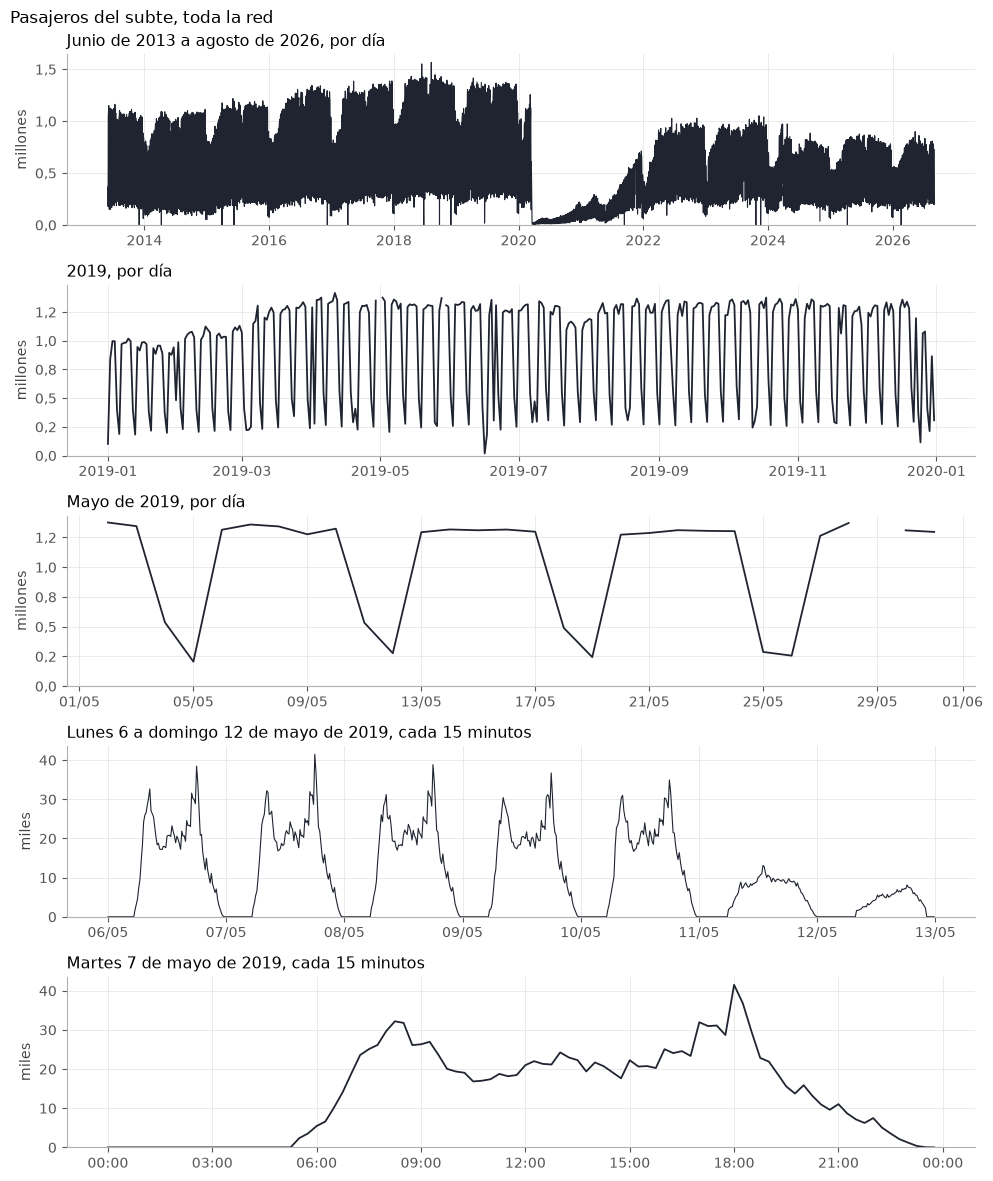

In [8]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12))
tramos = [
    (total, "Junio de 2013 a agosto de 2026, por día"),
    (total.loc["2019"], "2019, por día"),
    (total.loc["2019-05"], "Mayo de 2019, por día"),
    (grilla15("2019-05-06", "2019-05-12"), "Lunes 6 a domingo 12 de mayo de 2019, cada 15 minutos"),
    (grilla15("2019-05-07", "2019-05-07"), "Martes 7 de mayo de 2019, cada 15 minutos"),
]
for ax, (s, titulo) in zip(axes, tramos):
    ax.plot(s.index, s.values, color=TINTA, lw=0.8 if len(s) > 400 else 1.3)
    ax.set_title(titulo)
    ax.yaxis.set_major_formatter(en_millones if s.max() > 2e5 else en_miles)
    ax.set_ylabel("millones" if s.max() > 2e5 else "miles")
    ax.set_ylim(bottom=0)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
axes[4].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.suptitle("Pasajeros del subte, toda la red", x=0.01, ha="left", fontsize=12)
fig.tight_layout()

## 3. Frecuencia y agregación

`resample(regla)` agrupa las observaciones en intervalos de tiempo y les aplica una función. Algunas reglas: `"15min"`, `"h"` (hora), `"D"` (día), `"W-SUN"` (semanas de lunes a domingo, rotuladas con el domingo) y `"MS"` (mes, rotulado con el primer día).

Primero se completa la grilla de mayo de 2019: las franjas sin registros (la madrugada, por ejemplo) quedan en cero.

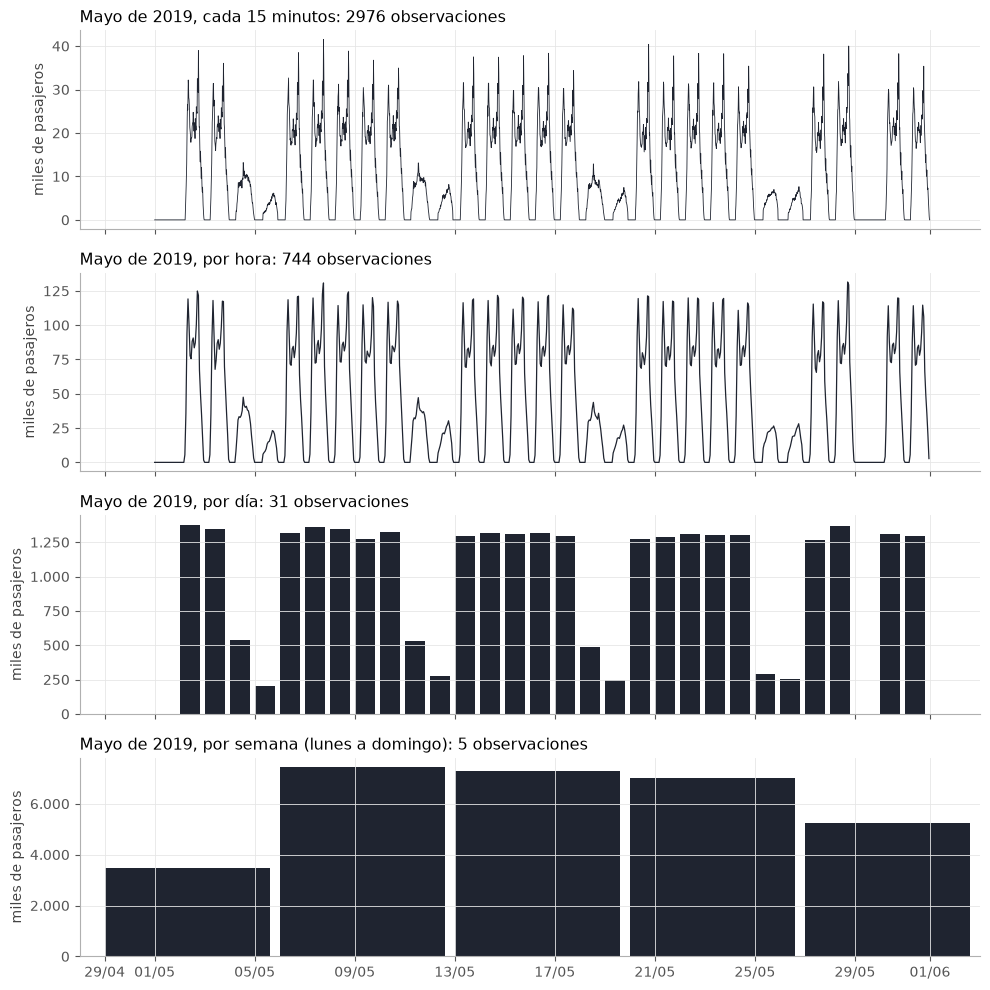

In [9]:
mayo15 = grilla15("2019-05-01", "2019-05-31")

reglas = {"15min": "cada 15 minutos", "h": "por hora", "D": "por día", "W-SUN": "por semana (lunes a domingo)"}
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
for ax, (regla, nombre) in zip(axes, reglas.items()):
    s = mayo15.resample(regla).sum()
    if regla in ("15min", "h"):
        ax.plot(s.index, s.values, color=TINTA, lw=0.6 if regla == "15min" else 0.9)
    elif regla == "D":
        ax.bar(s.index, s.values, width=0.8, align="edge", color=TINTA)
    else:
        ax.bar(s.index - pd.Timedelta(days=6), s.values, width=6.6, align="edge", color=TINTA)
    ax.set_title(f"Mayo de 2019, {nombre}: {len(s)} observaciones")
    ax.yaxis.set_major_formatter(en_miles)
    ax.set_ylabel("miles de pasajeros")
axes[-1].set_xlim(pd.Timestamp("2019-04-28"), pd.Timestamp("2019-06-03"))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout()

La primera y la última semana quedan incompletas (el mes no empieza en lunes ni termina en domingo): con la suma parecen semanas con pocos pasajeros. Con el promedio, en cambio, cada valor es el promedio de las franjas de 15 minutos del intervalo: misma forma que la suma, otra unidad.

In [10]:
suma = mayo15.resample("D").sum()
promedio = mayo15.resample("D").mean()
print("Suma / promedio, por día:", (suma / promedio).round(6).unique())

Suma / promedio, por día: [nan 96.]


Con los meses pasa algo parecido: la suma depende de cuántos días tiene el mes y de cuántos días faltan. El promedio diario de cada mes compara meses de distinto largo.

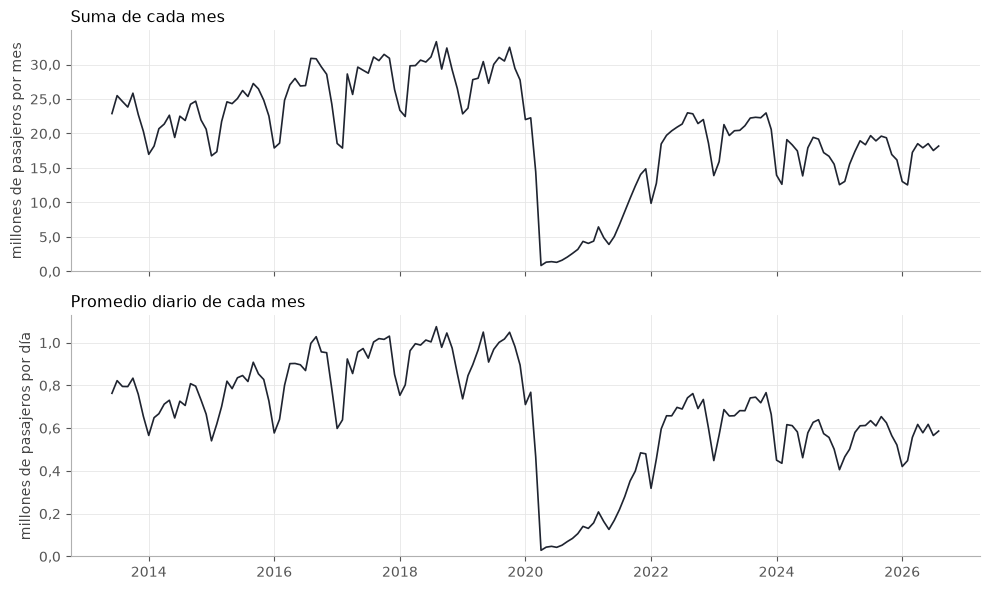

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (s, titulo, unidad) in zip(axes, [
    (total.resample("MS").sum(), "Suma de cada mes", "millones de pasajeros por mes"),
    (total.resample("MS").mean(), "Promedio diario de cada mes", "millones de pasajeros por día"),
]):
    ax.plot(s.index, s.values, color=TINTA, lw=1.2)
    ax.set_title(titulo)
    ax.set_ylabel(unidad)
    ax.yaxis.set_major_formatter(en_millones)
    ax.set_ylim(bottom=0)
fig.tight_layout()

## 4. Medias móviles

`rolling(k).mean()` reemplaza cada valor por el promedio de una ventana de `k` observaciones. Por defecto la ventana termina en el día (hacia atrás); con `center=True` queda centrada. `min_periods` permite calcular el promedio aunque falte algún día dentro de la ventana.

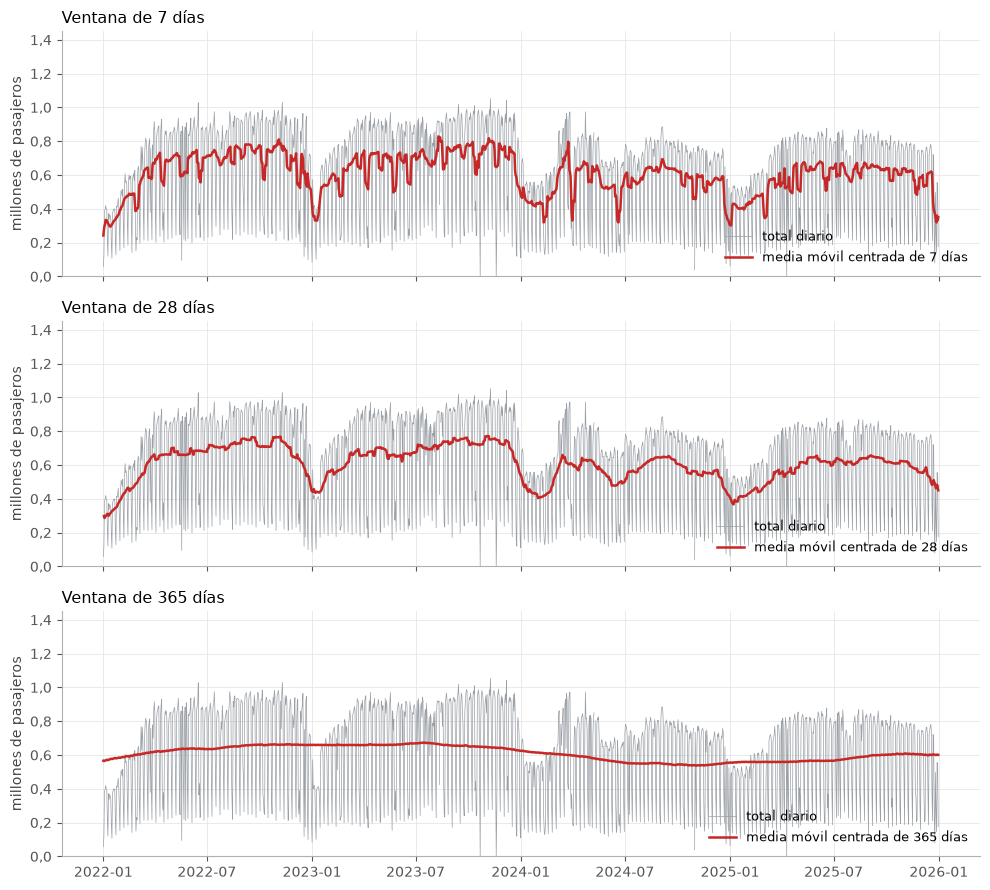

In [12]:
s = total.loc["2022":"2025"]
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, k in zip(axes, (7, 28, 365)):
    mm = s.rolling(k, center=True, min_periods=k // 2 + 1).mean()
    ax.plot(s.index, s.values, color=GRIS, lw=0.5, label="total diario")
    ax.plot(mm.index, mm.values, color=ROJO, lw=1.8, label=f"media móvil centrada de {k} días")
    ax.set_title(f"Ventana de {k} días")
    ax.yaxis.set_major_formatter(en_millones)
    ax.set_ylabel("millones de pasajeros")
    ax.set_ylim(0, 1.45e6)
    ax.legend(loc="lower right")
fig.tight_layout()

Una ventana de 7 días (o de un múltiplo de 7) contiene un lunes, un martes y así hasta el domingo: cada promedio pesa igual a todos los días de la semana y el ciclo semanal desaparece. Con 28 días se ven los meses, con las vacaciones de verano e invierno. Con 365 queda la tendencia.

La diferencia entre la ventana centrada y la ventana hacia atrás se ve en un cambio brusco, como el de marzo de 2020. La media hacia atrás solo usa datos pasados (es la que se puede calcular en tiempo real) y llega tarde a cada cambio.

Media centrada: primer día por debajo de la mitad del nivel de febrero: 2020-03-20
Media hacia atrás: primer día por debajo de la mitad del nivel de febrero: 2020-04-02


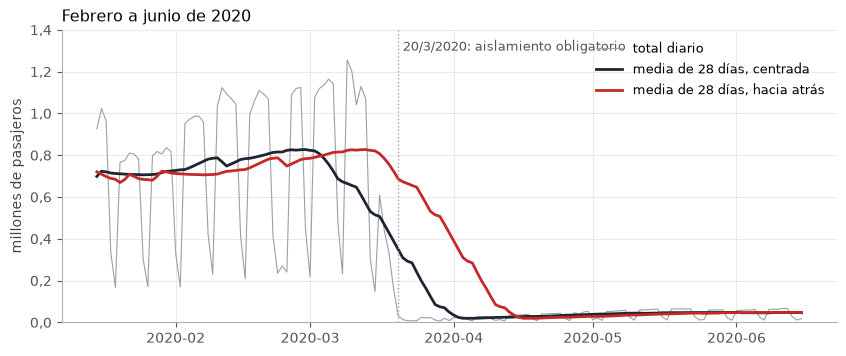

In [13]:
s = total.loc["2020-01-15":"2020-06-15"]
centrada = total.rolling(28, center=True, min_periods=15).mean().loc[s.index]
atras = total.rolling(28, min_periods=15).mean().loc[s.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(s.index, s.values, color=GRIS, lw=0.8, label="total diario")
ax.plot(centrada.index, centrada.values, color=TINTA, lw=2, label="media de 28 días, centrada")
ax.plot(atras.index, atras.values, color=ROJO, lw=2, label="media de 28 días, hacia atrás")
ax.axvline(pd.Timestamp("2020-03-20"), color=GRIS, ls=":", lw=1)
ax.text(pd.Timestamp("2020-03-21"), 1.3e6, "20/3/2020: aislamiento obligatorio", fontsize=9, color="#555555")
ax.yaxis.set_major_formatter(en_millones)
ax.set_ylabel("millones de pasajeros")
ax.set_ylim(0, 1.4e6)
ax.legend(loc="upper right")
ax.set_title("Febrero a junio de 2020")

nivel = total.loc["2020-02-01":"2020-02-29"].mean()
for nombre, m in (("centrada", centrada), ("hacia atrás", atras)):
    print(f"Media {nombre}: primer día por debajo de la mitad del nivel de febrero:", m[m < nivel / 2].index[0].date())

La media centrada empieza a bajar antes del 20 de marzo porque promedia días posteriores. La fecha del aislamiento sale del DNU 297/2020 ([Boletín Oficial, 20/3/2020](https://www.boletinoficial.gob.ar/detalleAviso/primera/227042/20200320)).

## 5. Hora por hora, día por día

Promedio de pasajeros en cada hora, separado por día de la semana, sin feriados ni días no laborables. Primero se suma cada hora de cada día y después se promedia sobre los días de cada tipo.

In [14]:
feriados = pd.read_csv(BASE + "feriados.csv", parse_dates=["fecha"])
feriados = feriados[(feriados["ambito"] == "nacional") | feriados["ambito"].str.startswith("CABA")]
no_habiles = set(feriados["fecha"])

def calor(por_hora):
    # por_hora: serie con índice horario (un valor por hora de cada día)
    df = por_hora.to_frame("valor")
    df["dia"] = df.index.normalize()
    df = df[~df["dia"].isin(no_habiles)]
    return df.groupby([df.index.day_of_week, df.index.hour])["valor"].mean().unstack()

subte_hora = quince.resample("h").sum()
subte_hora = subte_hora[subte_hora.index.normalize().isin(total.dropna().index)]   # solo días con datos

eco = pd.read_csv(BASE + "ecobici_hora.csv", parse_dates=["fecha"])
eco_hora = pd.Series(eco["viajes"].values, index=eco["fecha"] + pd.to_timedelta(eco["hora"], unit="h"))

calor_subte = {a: calor(subte_hora.loc[str(a)]) for a in (2019, 2025)}
calor_eco = calor(eco_hora.loc["2025"])
calor_subte[2025].round(0).astype(int).iloc[:, 5:12]

momento,5,6,7,8,9,10,11
momento,,,,,,,
0,3958,21347,54472,66107,50480,35520,36701
1,4032,21617,55917,69748,53561,37262,37903
2,3771,20558,53378,66372,51474,36235,37342
3,3832,20922,53459,67087,52333,37389,38145
4,3755,19839,49787,59014,47300,35373,37227
5,550,5562,11404,16553,19311,19905,22448
6,0,11,824,5084,6872,8553,10966


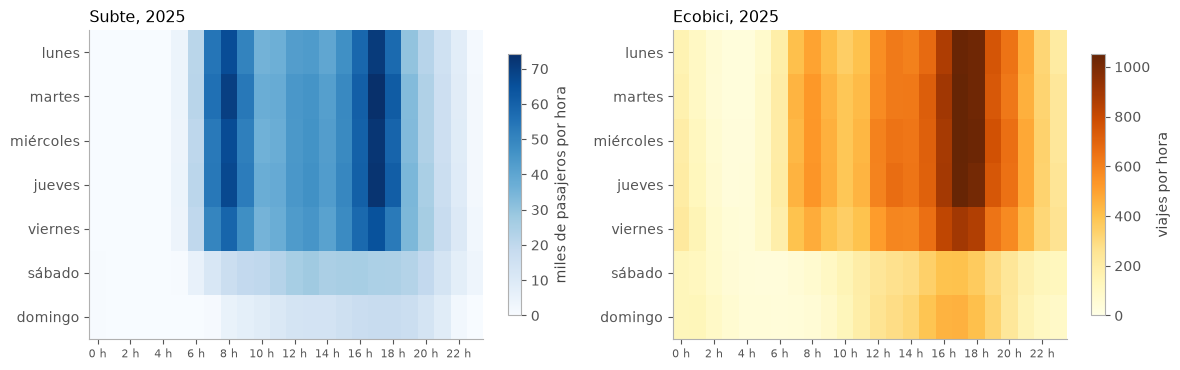

In [15]:
def dibujar_calor(ax, tabla, titulo, cmap, unidad, formato=None, **kw):
    im = ax.imshow(tabla.values, aspect="auto", cmap=cmap, **kw)
    ax.set_yticks(range(7), DIAS)
    ax.set_xticks(range(0, 24, 2), [f"{h} h" for h in range(0, 24, 2)], fontsize=8)
    ax.grid(False)
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, label=unidad, shrink=0.85, format=formato)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
dibujar_calor(axes[0], calor_subte[2025], "Subte, 2025", "Blues", "miles de pasajeros por hora", formato=en_miles, vmin=0)
dibujar_calor(axes[1], calor_eco, "Ecobici, 2025", "YlOrBr", "viajes por hora", vmin=0)
fig.tight_layout()

El subte tiene dos picos los días hábiles (mañana y tarde) y casi nada de noche. Ecobici tiene un pico a la mañana, otro a la tarde, y los fines de semana se reparte durante la tarde. Cada panel tiene su propia escala: lo que se compara es la forma.

Comparando 2025 con 2019 hora por hora:

Pico de la mañana (7 a 9 h), lunes a jueves: 65 % del nivel de 2019
Pico de la mañana, viernes: 60 %
Domingos, todo el día: 72 %
En 2025, un sábado tiene 47 % de los pasajeros de un día de lunes a jueves; un domingo, 25 %


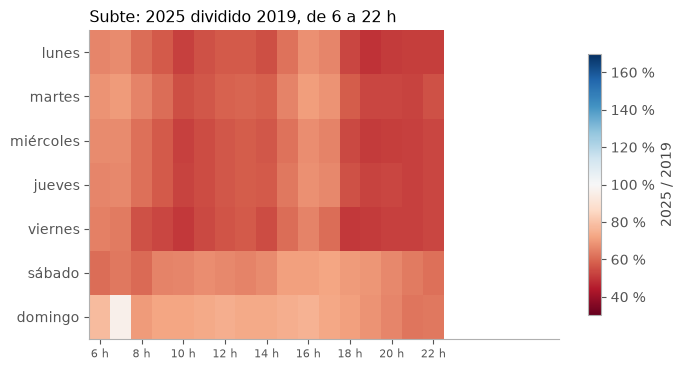

In [16]:
from matplotlib.colors import TwoSlopeNorm

cociente = calor_subte[2025] / calor_subte[2019]
fig, ax = plt.subplots(figsize=(7, 3.8))
dibujar_calor(ax, cociente.loc[:, 6:22], "Subte: 2025 dividido 2019, de 6 a 22 h", "RdBu",
              "2025 / 2019", formato=FuncFormatter(lambda v, _: pct(v)), norm=TwoSlopeNorm(vcenter=1, vmin=0.3, vmax=1.7))
ax.set_xticks(range(0, 17, 2), [f"{h} h" for h in range(6, 23, 2)], fontsize=8)
fig.tight_layout()

tot = {a: t.loc[:, 5:23].sum(axis=1) for a, t in calor_subte.items()}
print("Pico de la mañana (7 a 9 h), lunes a jueves:", pct(cociente.loc[0:3, 7:8].values.mean()), "del nivel de 2019")
print("Pico de la mañana, viernes:", pct(cociente.loc[4, 7:8].mean()))
print("Domingos, todo el día:", pct(tot[2025][6] / tot[2019][6]))
print("En 2025, un sábado tiene", pct(tot[2025][5] / tot[2025][0:3].mean()), "de los pasajeros de un día de lunes a jueves; un domingo,", pct(tot[2025][6] / tot[2025][0:3].mean()))

## 6. Días atípicos

Para encontrar días raros se compara cada día con días parecidos: el mismo día de la semana en las cuatro semanas anteriores y las cuatro siguientes. El cociente entre el valor del día y la mediana de esos ocho días dice cuánto se aparta. La mediana, a diferencia del promedio, no se mueve si una de las semanas de referencia también tuvo un día raro.

Como el índice tiene todos los días (los faltantes están como vacíos), `shift(7)` es el valor de siete días antes y `shift(-7)` el de siete días después.

Días con cociente: 4818 | atípicos (menos de 0,7 o más de 1,3): 402


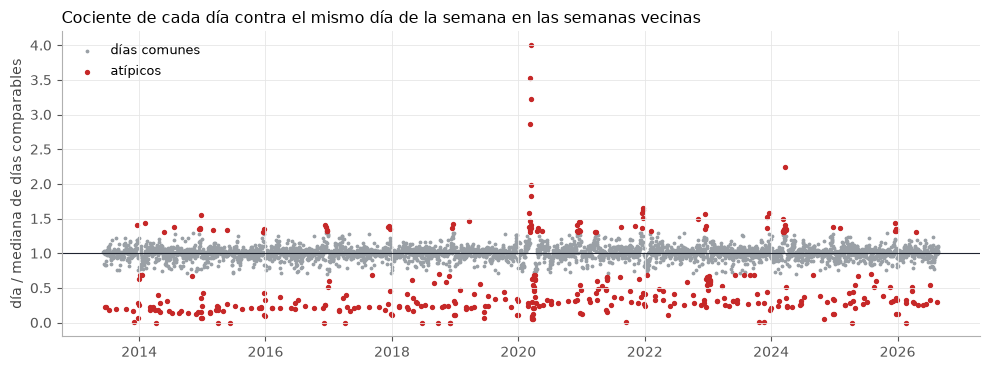

In [17]:
vecinos = pd.concat([total.shift(k) for k in (-28, -21, -14, -7, 7, 14, 21, 28)], axis=1)
referencia = vecinos.median(axis=1)
cociente = (total / referencia).where(vecinos.notna().sum(axis=1) >= 5)

atipico = (cociente < 0.7) | (cociente > 1.3)
print("Días con cociente:", cociente.notna().sum(), "| atípicos (menos de 0,7 o más de 1,3):", atipico.sum())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(cociente.index[~atipico], cociente[~atipico], s=3, color=GRIS, label="días comunes")
ax.scatter(cociente.index[atipico], cociente[atipico], s=8, color=ROJO, label="atípicos")
ax.axhline(1, color=TINTA, lw=0.8)
ax.set_ylabel("día / mediana de días comparables")
ax.set_title("Cociente de cada día contra el mismo día de la semana en las semanas vecinas")
ax.legend(loc="upper left")
fig.tight_layout()

`eventos_verificados.csv` tiene, para los días atípicos del subte, qué pasó y la fuente (notas de prensa, decretos, resoluciones). Se armó con este mismo cociente. El cruce por fecha muestra qué tipo de hecho hay detrás de los días que encontramos.

In [18]:
eventos = pd.read_csv(BASE + "eventos_verificados.csv", parse_dates=["fecha"])
dias_atipicos = cociente[atipico].rename("cociente").to_frame()
cruce = dias_atipicos.join(eventos.set_index("fecha")[["tipo", "descripcion", "fuente_url", "confianza"]])
print("Atípicos con explicación en eventos_verificados:", cruce["tipo"].notna().sum(), "de", len(cruce))
cruce["tipo"].fillna("(sin fila en eventos_verificados)").value_counts()

Atípicos con explicación en eventos_verificados: 295 de 402


tipo
feriado                              159
(sin fila en eventos_verificados)    107
otro                                  54
puente                                27
sin_explicar                          12
cierre_obras                          11
evento_masivo                         10
paro_general                           9
datos_incompletos                      5
paro_subte                             4
clima                                  2
elecciones                             2
Name: count, dtype: int64

La mayoría son feriados y puentes. Sin ellos quedan paros, cortes de servicio, elecciones con subte gratuito (los molinetes no cuentan a quien no paga), eventos masivos, y días cuya referencia está distorsionada (por ejemplo, semanas de fin de año). Los diez días más bajos que no son feriado ni puente:

In [19]:
pd.set_option("display.max_colwidth", 140)
otros = cruce[~cruce["tipo"].isin(["feriado", "puente"]) & cruce["tipo"].notna()]
otros.sort_values("cociente").head(10)[["cociente", "tipo", "descripcion"]].round(3)

,cociente,tipo,descripcion
fecha,,,
2018-11-30,0.0,evento_masivo,Cumbre del G20 en Buenos Aires: el subte no funcionó (todas las líneas y el Premetro) y fue feriado en la Ciudad por el Decreto 967/2018.
2018-09-25,0.0,paro_general,Paro general de la CGT y las dos CTA: el subte dejó de funcionar a las 20 del lunes 24 y no hubo servicio en ninguna línea el martes 25.
2017-04-06,0.0,paro_general,Primer paro general de la CGT contra el gobierno de Macri: no funcionaron las seis líneas ni el Premetro.
2015-06-09,0.0,paro_general,"Paro general de los gremios del transporte, la CGT de Moyano y la CTA de Micheli: desde las 0 h no hubo colectivos, trenes ni subtes."
2018-06-25,0.0,paro_general,"Paro general de la CGT: sin servicio de trenes, subtes ni colectivos."
2015-03-31,0.0,paro_general,"Paro nacional del transporte contra el impuesto a las Ganancias: paro total en colectivos, trenes, subtes y Premetro."
2018-12-01,0.0,evento_masivo,Segundo día de la cumbre del G20: el subte no funcionó en ninguna línea ni en el Premetro.
2026-02-19,0.0,paro_general,"Paro general de la CGT contra la reforma laboral: la AGTSyP anunció paro total de subte y Premetro de 0 a 24 h (en los datos, cero pasaj..."
2016-12-07,0.0,paro_subte,Paro total de los gremios del subte por tiempo indeterminado tras la muerte de un trabajador electrocutado en el taller Colonia de la lí...


### ¿Qué pasó este día?

El total diario esconde la forma del día. Comparando el perfil cada 15 minutos de un día raro con la mediana del mismo día de la semana en semanas normales se ve a qué hora empezó o terminó lo que pasó. La referencia excluye feriados y semanas cuyo total se aparta más de 20 % de la mediana.

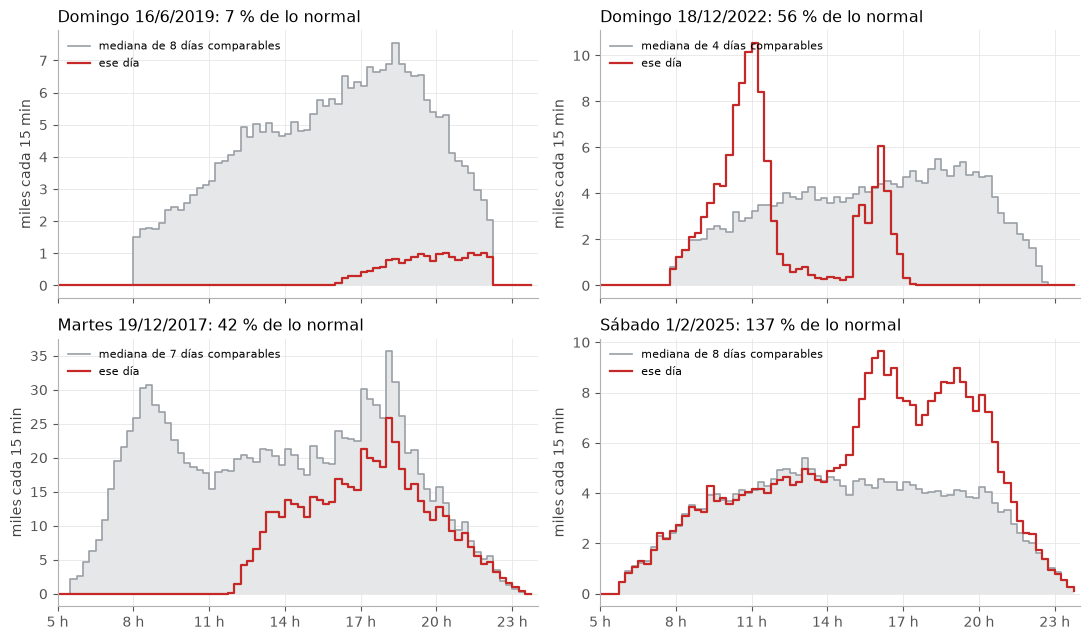

In [20]:
perfiles = q.groupby(["fecha", "desde"])["pax"].sum().unstack(fill_value=0)
perfiles.index = pd.to_datetime(perfiles.index)
perfiles = perfiles.reindex(columns=pd.date_range("2000-01-01", periods=96, freq="15min").strftime("%H:%M"), fill_value=0)

def perfil_y_referencia(fecha):
    f = pd.Timestamp(fecha)
    cand = [f + pd.Timedelta(days=7 * k) for k in (-4, -3, -2, -1, 1, 2, 3, 4)]
    cand = [c for c in cand if c in perfiles.index and c not in no_habiles]
    tot = perfiles.loc[cand].sum(axis=1)
    cand = [c for c in cand if 0.8 <= tot[c] / tot.median() <= 1.2]
    return perfiles.loc[f], perfiles.loc[cand].median(), len(cand)

casos = ["2019-06-16", "2022-12-18", "2017-12-19", "2025-02-01"]
horas = np.arange(96) / 4
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, fecha in zip(axes.flat, casos):
    dia, ref, n = perfil_y_referencia(fecha)
    ax.fill_between(horas, ref.values, step="post", color=GRIS, alpha=0.25, lw=0)
    ax.step(horas, ref.values, where="post", color=GRIS, lw=1.2, label=f"mediana de {n} días comparables")
    ax.step(horas, dia.values, where="post", color=ROJO, lw=1.6, label="ese día")
    f = pd.Timestamp(fecha)
    ax.set_title(f"{DIAS[f.day_of_week].capitalize()} {f.day}/{f.month}/{f.year}: {pct(dia.sum() / ref.sum())} de lo normal")
    ax.set_xlim(5, 24)
    ax.set_xticks(range(5, 25, 3), [f"{h} h" for h in range(5, 25, 3)])
    ax.yaxis.set_major_formatter(en_miles)
    ax.set_ylabel("miles cada 15 min")
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()

In [21]:
for fecha in casos:
    fila = eventos.loc[eventos["fecha"] == fecha].iloc[0]
    print(f"{fecha}: {fila['descripcion']}\n   Fuente: {fila['fuente_url']}\n")

2019-06-16: Apagón nacional: el subte no inició el servicio; la línea A se normalizó minutos antes de las 16 y el resto de las líneas volvió en forma escalonada.
   Fuente: https://www.infobae.com/sociedad/2019/06/16/no-funcionan-trenes-y-subtes-por-el-masivo-apagon-en-todo-el-pais/

2022-12-18: Final del Mundial de Qatar: casi sin pasajeros durante el partido y, desde las 17:05, toda la red paralizada por seguridad durante los festejos.
   Fuente: https://www.lanacion.com.ar/buenos-aires/por-los-festejos-masivos-la-red-de-subte-portena-esta-paralizada-para-garantizar-la-seguridad-de-la-nid18122022/

2017-12-19: Los metrodelegados interrumpieron el subte desde las 21 del lunes 18 (paro de la CGT contra la reforma previsional) hasta el mediodía del martes 19; en los datos hay cero pasajeros hasta las 12.
   Fuente: https://www.infobae.com/politica/2017/12/18/como-afectara-al-transporte-de-pasajeros-el-paro-convocado-por-la-cgt/

2025-02-01: Marcha Federal del Orgullo Antifascista y Anti

## Para seguir

1. Repetir el mapa de calor con `subte_15min_linea.csv.gz` para una sola línea (por ejemplo, la H o la E) y compararlo con el del total. ¿Qué líneas tienen un pico de la tarde más alto que el de la mañana?
2. Aplicar el método de los días atípicos a `ecobici_diario.csv`. ¿Qué días son atípicos en las dos series a la vez? ¿Cuáles lo son en Ecobici y no en el subte? (Ayuda: cruzar con la lluvia de `clima_diario.csv`.)
3. Cambiar los umbrales de 0,7 y 1,3 y contar cuántos días atípicos quedan sin fila en `eventos_verificados.csv`. Mirar el perfil de 15 minutos de alguno de ellos.